In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../dataset/city_day.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (29531, 16)


In [3]:
df.head()


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.6 MB


In [5]:
df.describe()

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000


In [6]:
missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_table = missing_table.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_table

,Missing Values,Missing Percentage
Xylene,18109,61.322001
PM10,11140,37.723071
NH3,10328,34.973418
Toluene,8041,27.229014
Benzene,5623,19.041008
AQI,4681,15.851139
AQI_Bucket,4681,15.851139
PM2.5,4598,15.570079
NOx,4185,14.171549
O3,4022,13.619586


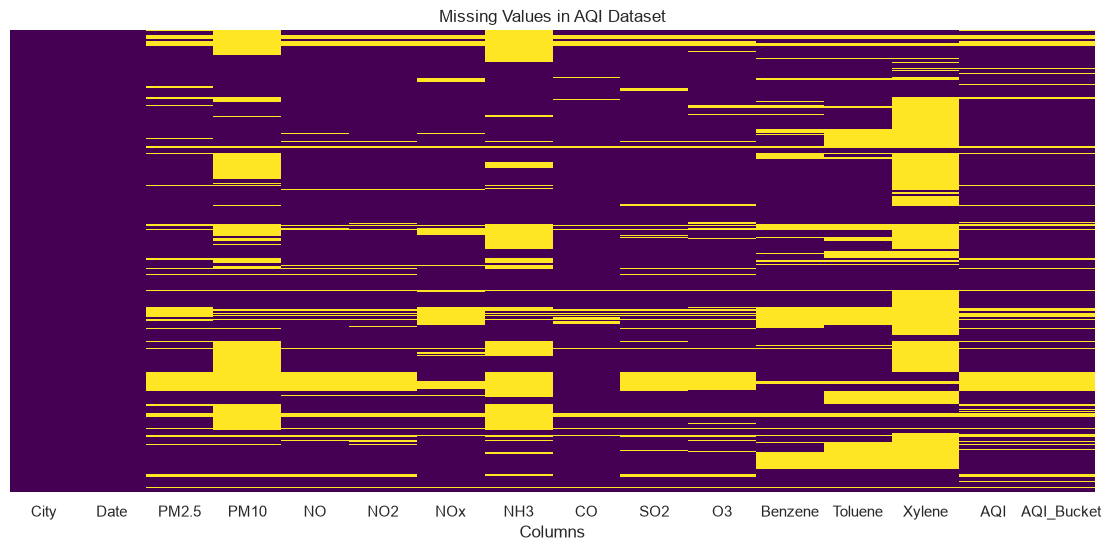

In [7]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in AQI Dataset")
plt.xlabel("Columns")
plt.show()

In [8]:
print("Total rows:", len(df))

print("Rows with missing AQI:", df["AQI"].isnull().sum())

print("Rows with available AQI:", df["AQI"].notnull().sum())

Total rows: 29531
Rows with missing AQI: 4681
Rows with available AQI: 24850


In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [10]:
print("Duplicate City-Date records:",
      df.duplicated(subset=["City", "Date"]).sum())

Duplicate City-Date records: 0


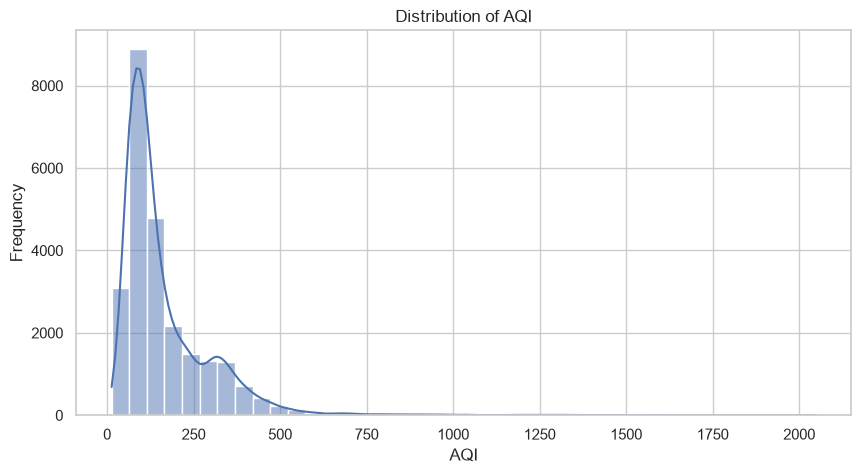

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(df["AQI"].dropna(), bins=40, kde=True)

plt.title("Distribution of AQI")
plt.xlabel("AQI")
plt.ylabel("Frequency")

plt.show()

In [12]:
df["AQI"].describe()

count    24850.000000
mean       166.463581
std        140.696585
min         13.000000
25%         81.000000
50%        118.000000
75%        208.000000
max       2049.000000
Name: AQI, dtype: float64

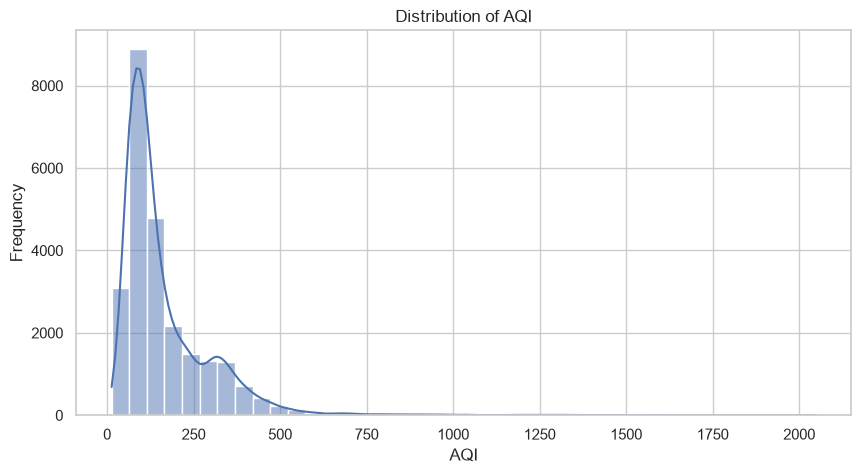

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(df["AQI"].dropna(), bins=40, kde=True)

plt.title("Distribution of AQI")
plt.xlabel("AQI")
plt.ylabel("Frequency")

plt.show()

In [16]:
df["AQI"].describe()

count    24850.000000
mean       166.463581
std        140.696585
min         13.000000
25%         81.000000
50%        118.000000
75%        208.000000
max       2049.000000
Name: AQI, dtype: float64

In [17]:
city_aqi = df.groupby("City")["AQI"].mean().sort_values(ascending=False)

city_aqi

City
Ahmedabad             452.122939
Delhi                 259.487744
Patna                 240.782042
Gurugram              225.123882
Lucknow               217.973059
Talcher               172.886819
Jorapokhar            159.251621
Brajrajnagar          150.280505
Kolkata               140.566313
Guwahati              140.111111
Jaipur                133.679159
Bhopal                132.827338
Amritsar              119.920959
Visakhapatnam         117.269855
Chennai               114.502654
Hyderabad             109.207447
Mumbai                105.352258
Kochi                 104.284810
Chandigarh             96.498328
Amaravati              95.299643
Bengaluru              94.318325
Ernakulam              92.359477
Thiruvananthapuram     75.878327
Coimbatore             73.023256
Shillong               53.795122
Aizawl                 34.765766
Name: AQI, dtype: float64

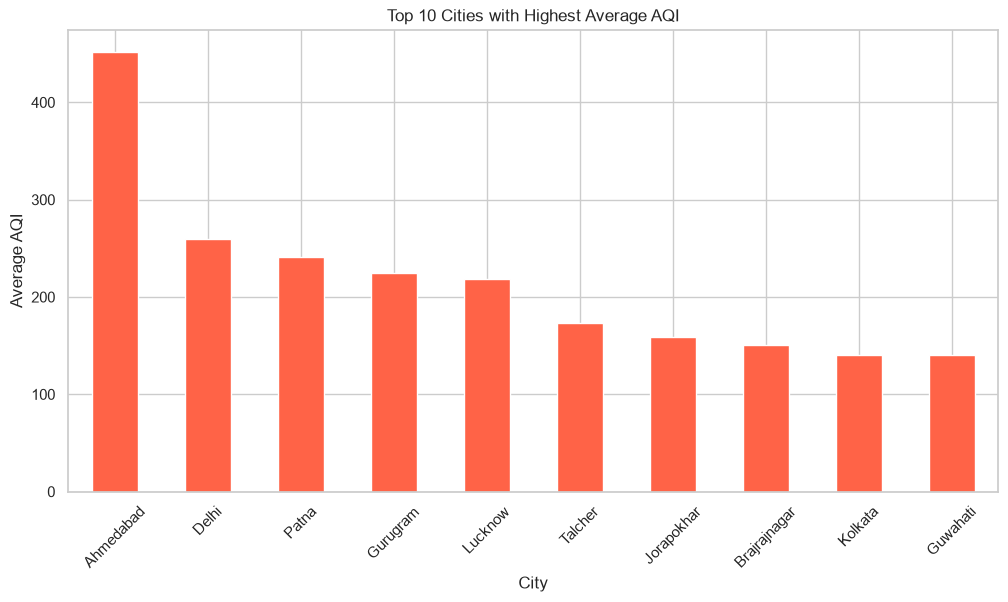

In [18]:
plt.figure(figsize=(12, 6))

city_aqi.head(10).plot(kind="bar", color="tomato")

plt.title("Top 10 Cities with Highest Average AQI")
plt.xlabel("City")
plt.ylabel("Average AQI")
plt.xticks(rotation=45)

plt.show()

In [ ]:
df["AQI_Bucket"].value_counts()

AQI_Bucket
Moderate        8829
Satisfactory    8224
Poor            2781
Very Poor       2337
Good            1341
Severe          1338
Name: count, dtype: int64

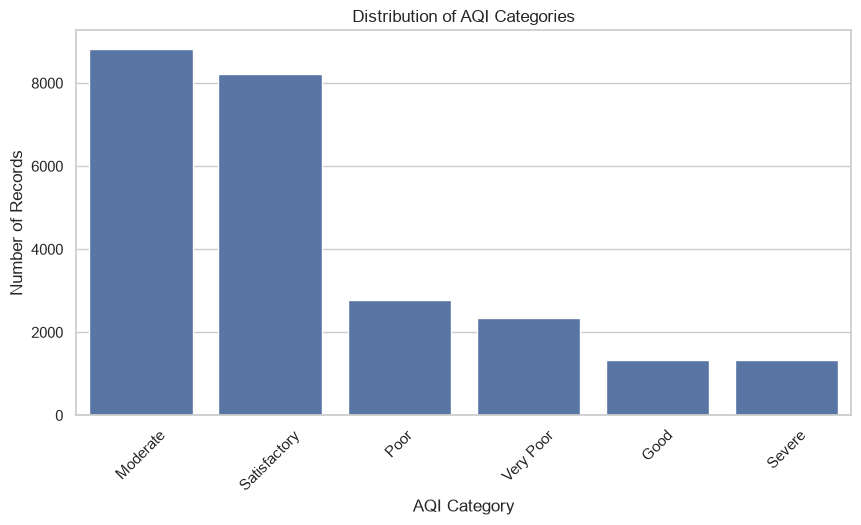

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="AQI_Bucket", order=df["AQI_Bucket"].value_counts().index)

plt.title("Distribution of AQI Categories")
plt.xlabel("AQI Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)

plt.show()

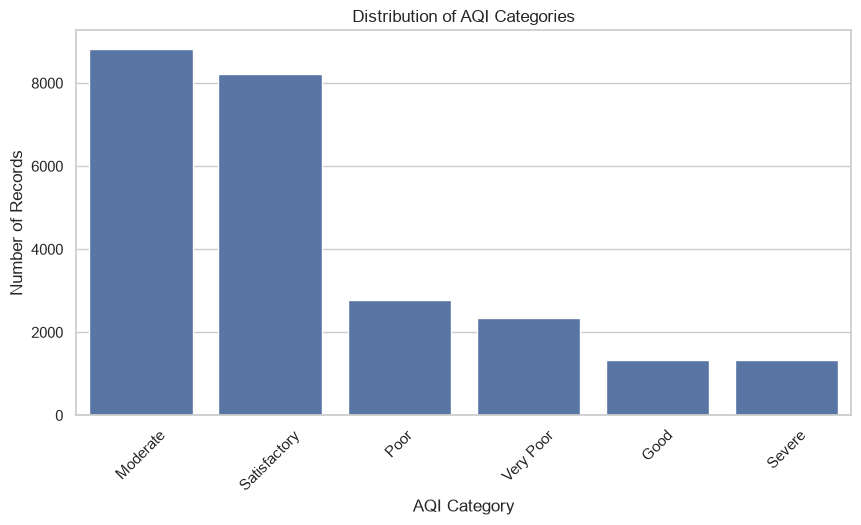

In [21]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="AQI_Bucket", order=df["AQI_Bucket"].value_counts().index)

plt.title("Distribution of AQI Categories")
plt.xlabel("AQI Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)

plt.show()

In [22]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

correlation

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
PM2.5,1.000000,0.846498,0.433491,0.350709,0.436792,0.275086,0.089912,0.132325,0.161238,0.023911,0.117080,0.114579,0.659181
PM10,0.846498,1.000000,0.502349,0.464380,0.527768,0.376816,0.112588,0.256974,0.244919,0.022265,0.169335,0.081700,0.803313
NO,0.433491,0.502349,1.000000,0.478070,0.794890,0.185621,0.212607,0.170322,0.014580,0.035771,0.150857,0.094237,0.452191
NO2,0.350709,0.464380,0.478070,1.000000,0.627627,0.234938,0.356521,0.392233,0.293349,0.025260,0.273926,0.171701,0.537071
NOx,0.436792,0.527768,0.794890,0.627627,1.000000,0.166224,0.226992,0.238397,0.093170,0.039121,0.189386,0.087398,0.486450
NH3,0.275086,0.376816,0.185621,0.234938,0.166224,1.000000,0.104891,-0.038998,0.094972,-0.015650,0.013227,-0.019813,0.252019
CO,0.089912,0.112588,0.212607,0.356521,0.226992,0.104891,1.000000,0.489697,0.041736,0.061861,0.277904,0.154889,0.683346
SO2,0.132325,0.256974,0.170322,0.392233,0.238397,-0.038998,0.489697,1.000000,0.162142,0.036110,0.296139,0.251195,0.490586
O3,0.161238,0.244919,0.014580,0.293349,0.093170,0.094972,0.041736,0.162142,1.000000,0.020255,0.130209,0.111410,0.198991
Benzene,0.023911,0.022265,0.035771,0.025260,0.039121,-0.015650,0.061861,0.036110,0.020255,1.000000,0.739286,0.415427,0.044407


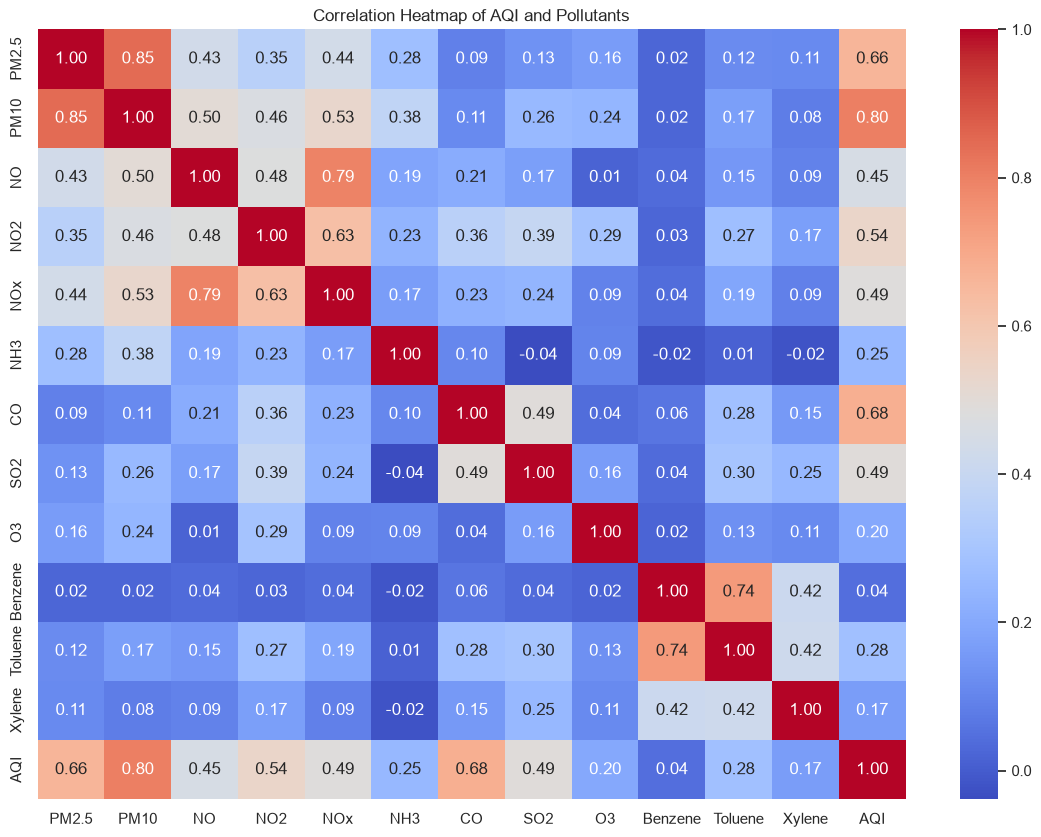

In [23]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of AQI and Pollutants")
plt.show()

In [24]:
aqi_correlation = correlation["AQI"].sort_values(ascending=False)

aqi_correlation

AQI        1.000000
PM10       0.803313
CO         0.683346
PM2.5      0.659181
NO2        0.537071
SO2        0.490586
NOx        0.486450
NO         0.452191
Toluene    0.279992
NH3        0.252019
O3         0.198991
Xylene     0.165532
Benzene    0.044407
Name: AQI, dtype: float64

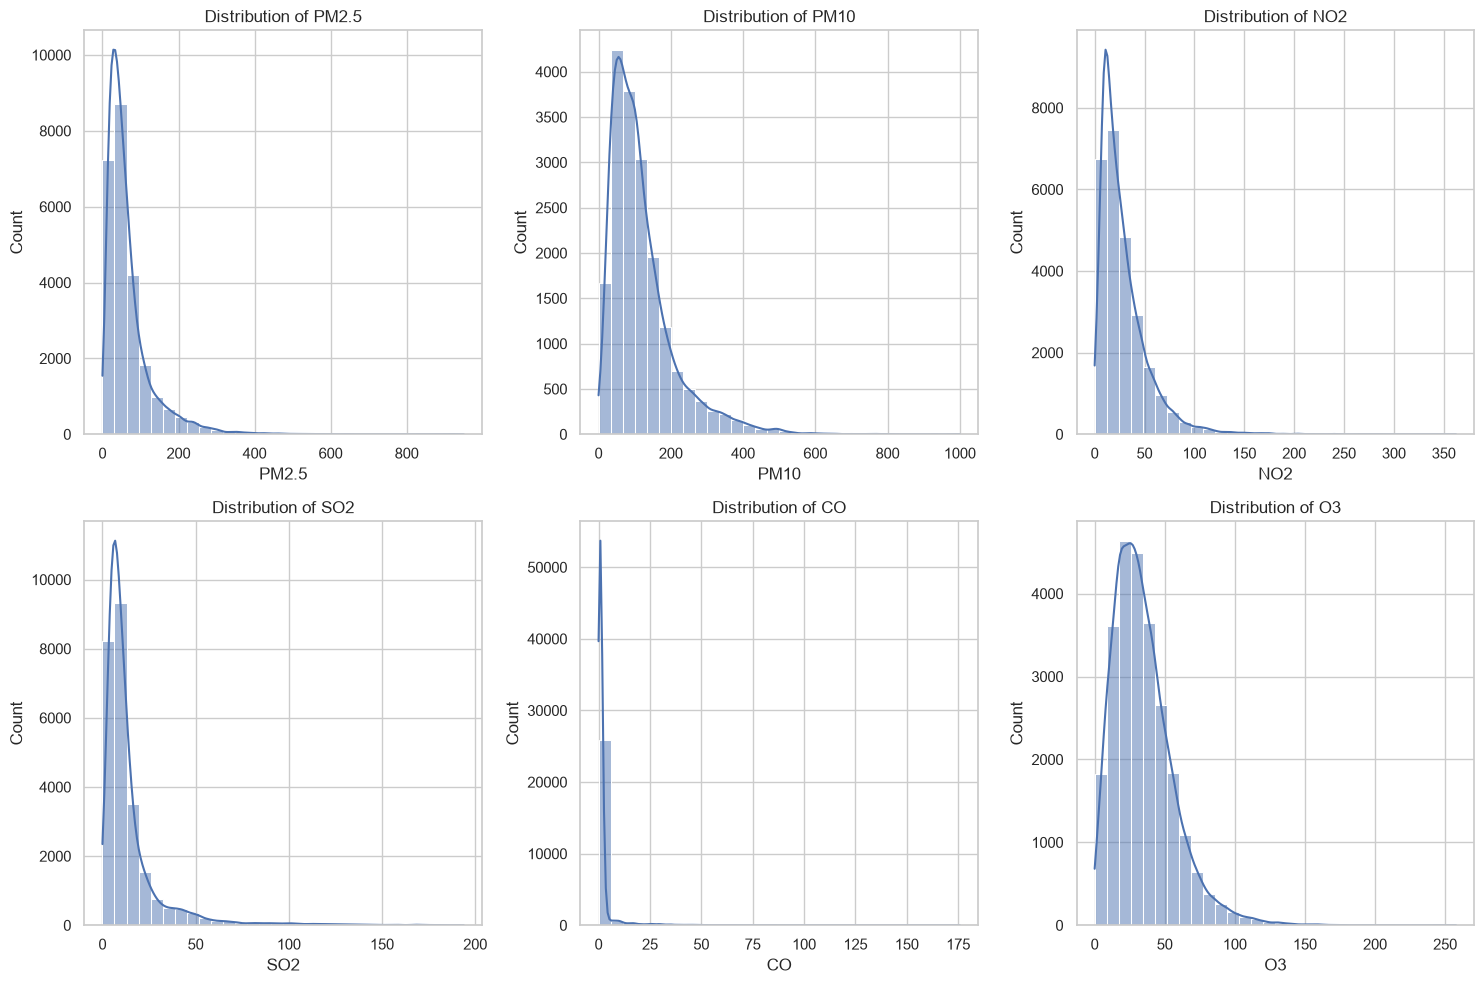

In [25]:
pollutants = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3"]

plt.figure(figsize=(15, 10))

for i, column in enumerate(pollutants, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[column].dropna(), bins=30, kde=True)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)

plt.tight_layout()
plt.show()

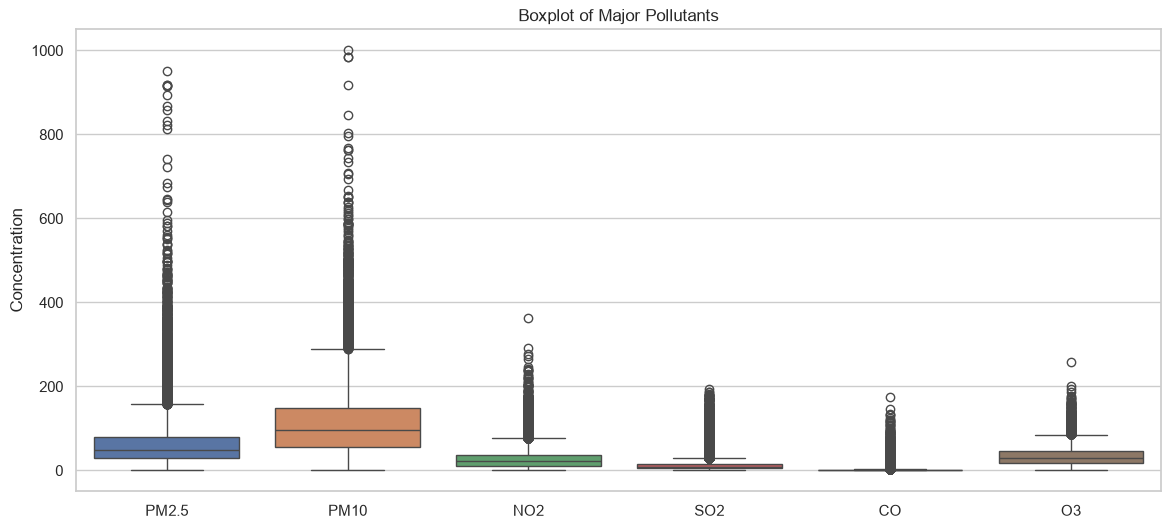

In [26]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=df[pollutants])

plt.title("Boxplot of Major Pollutants")
plt.ylabel("Concentration")
plt.show()

univariate analysis

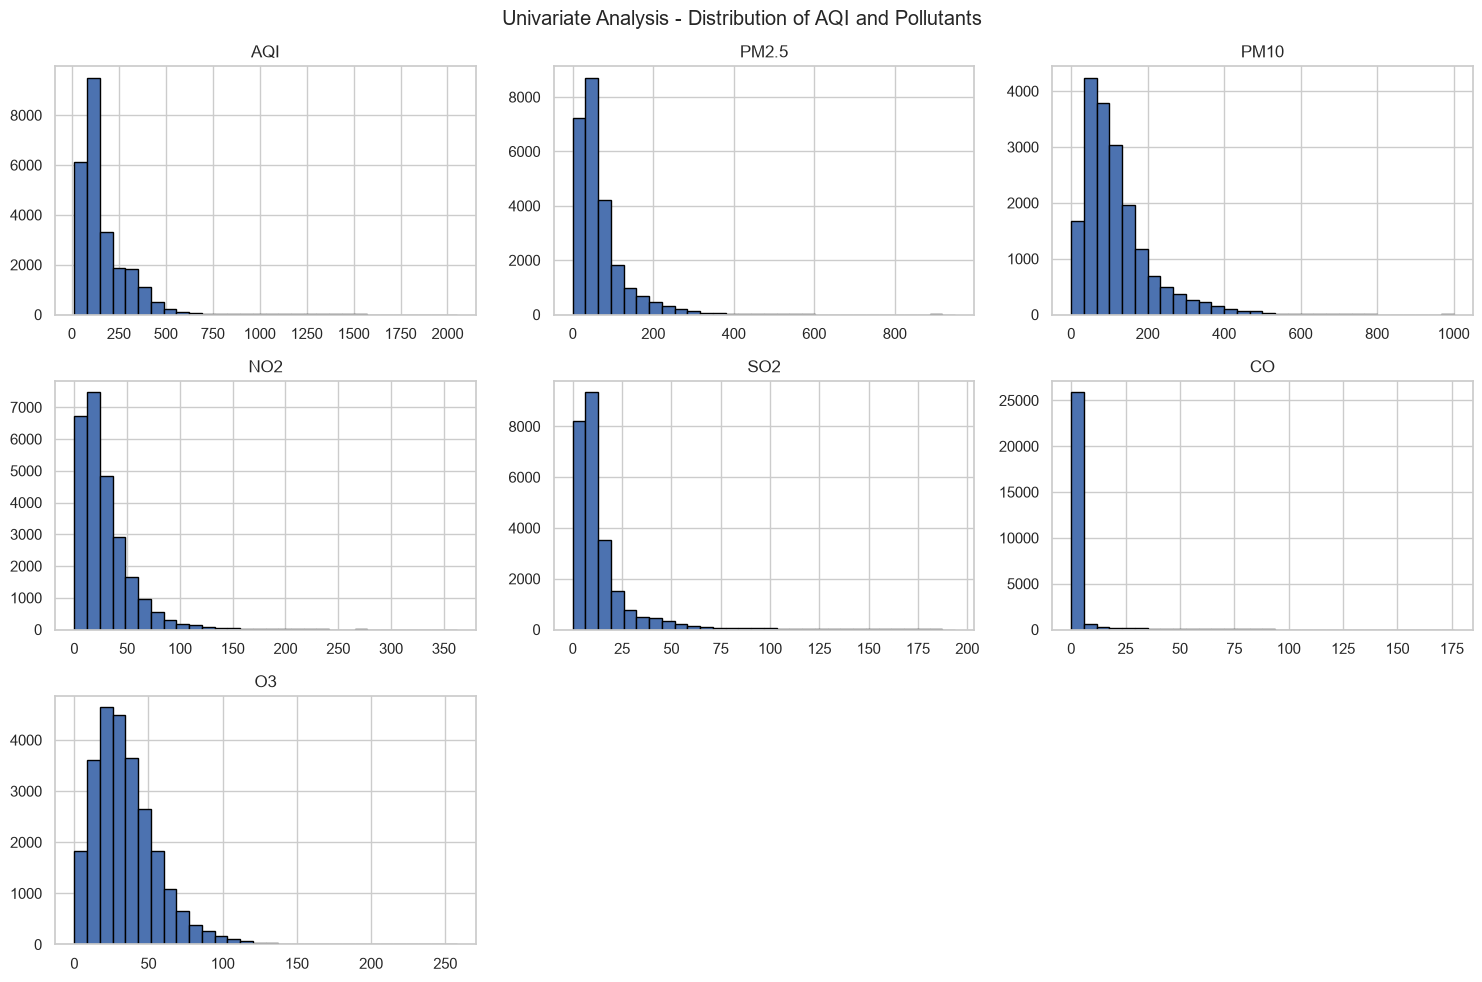

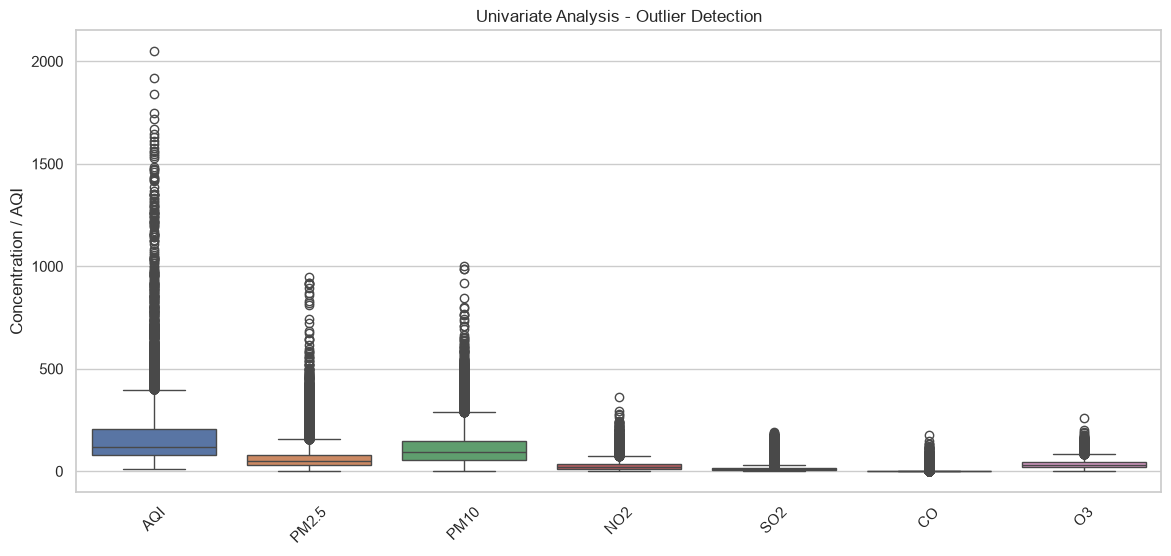

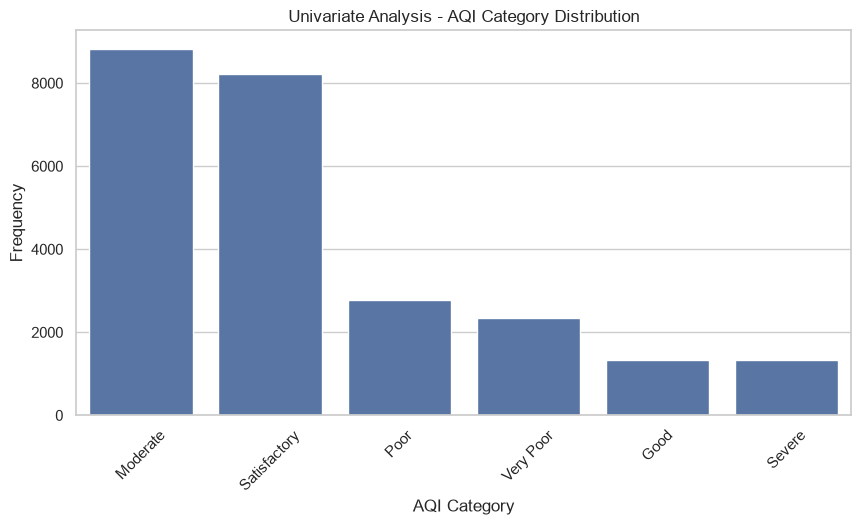

Statistical Summary:


,AQI,PM2.5,PM10,NO2,SO2,CO,O3
count,24850.000000,24933.000000,18391.000000,25946.000000,25677.000000,27472.000000,25509.000000
mean,166.463581,67.450578,118.127103,28.560659,14.531977,2.248598,34.491430
std,140.696585,64.661449,90.605110,24.474746,18.133775,6.962884,21.694928
min,13.000000,0.040000,0.010000,0.010000,0.010000,0.000000,0.010000
25%,81.000000,28.820000,56.255000,11.750000,5.670000,0.510000,18.860000
50%,118.000000,48.570000,95.680000,21.690000,9.160000,0.890000,30.840000
75%,208.000000,80.590000,149.745000,37.620000,15.220000,1.450000,45.570000
max,2049.000000,949.990000,1000.000000,362.210000,193.860000,175.810000,257.730000


AQI Category Counts:


AQI_Bucket
Moderate        8829
Satisfactory    8224
Poor            2781
Very Poor       2337
Good            1341
Severe          1338
Name: count, dtype: int64

In [27]:
# UNIVARIATE ANALYSIS

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Numerical variables
numeric_columns = [
    "AQI", "PM2.5", "PM10", "NO2",
    "SO2", "CO", "O3"
]

# 1. Histograms for numerical variables
df[numeric_columns].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Univariate Analysis - Distribution of AQI and Pollutants")
plt.tight_layout()
plt.show()

# 2. Boxplots for numerical variables
plt.figure(figsize=(14, 6))

sns.boxplot(data=df[numeric_columns])

plt.title("Univariate Analysis - Outlier Detection")
plt.ylabel("Concentration / AQI")
plt.xticks(rotation=45)
plt.show()

# 3. AQI Category distribution
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="AQI_Bucket",
    order=df["AQI_Bucket"].value_counts().index
)

plt.title("Univariate Analysis - AQI Category Distribution")
plt.xlabel("AQI Category")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.show()

# 4. Statistical summary
print("Statistical Summary:")
display(df[numeric_columns].describe())

# 5. AQI category frequency
print("AQI Category Counts:")
display(df["AQI_Bucket"].value_counts())

bivariate analysis

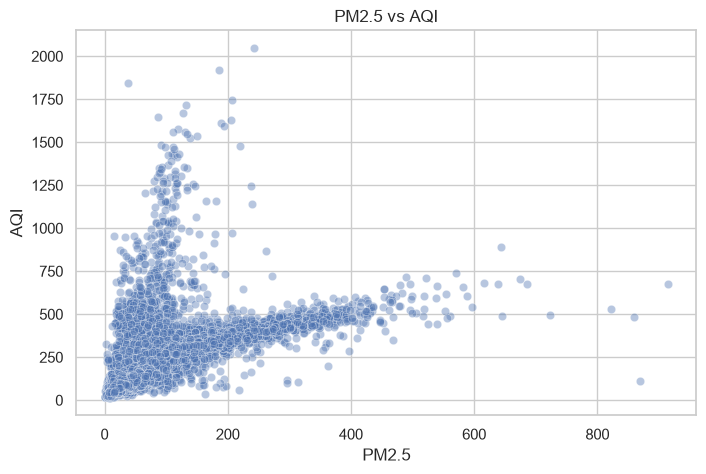

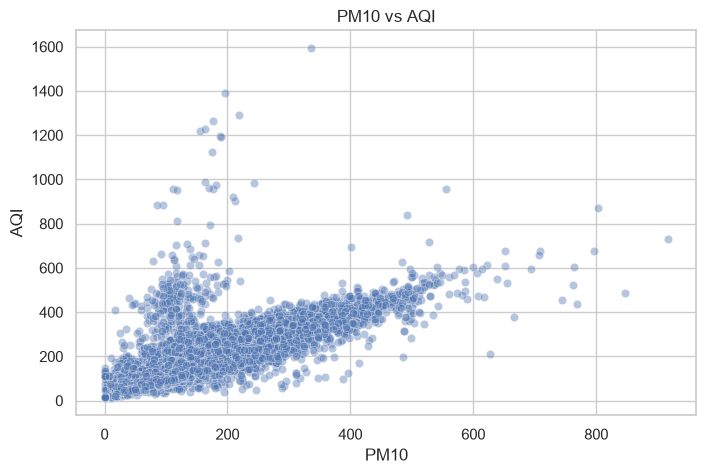

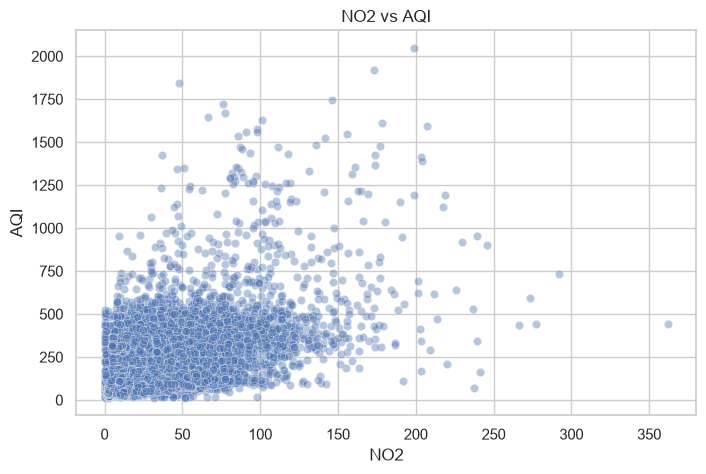

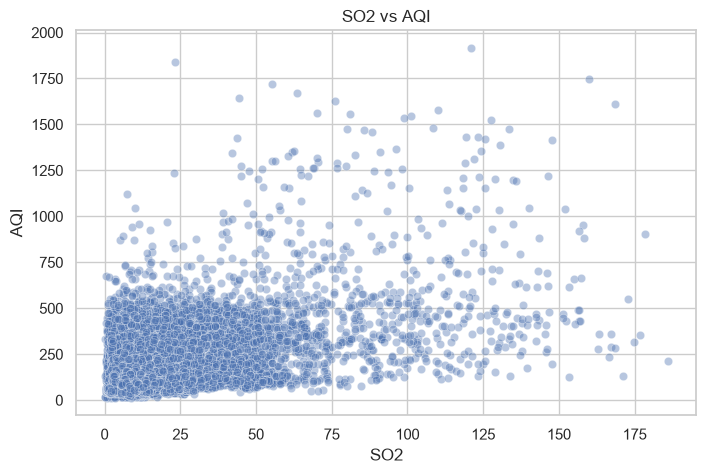

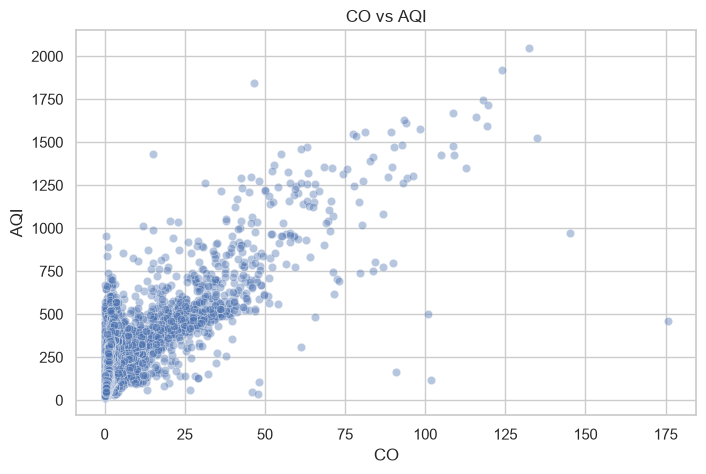

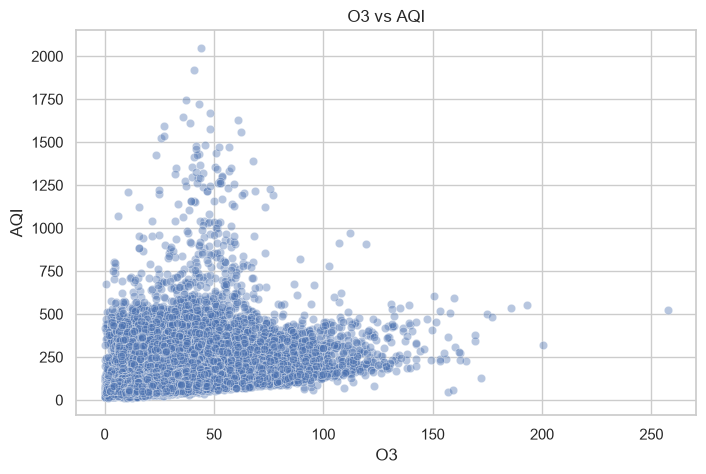

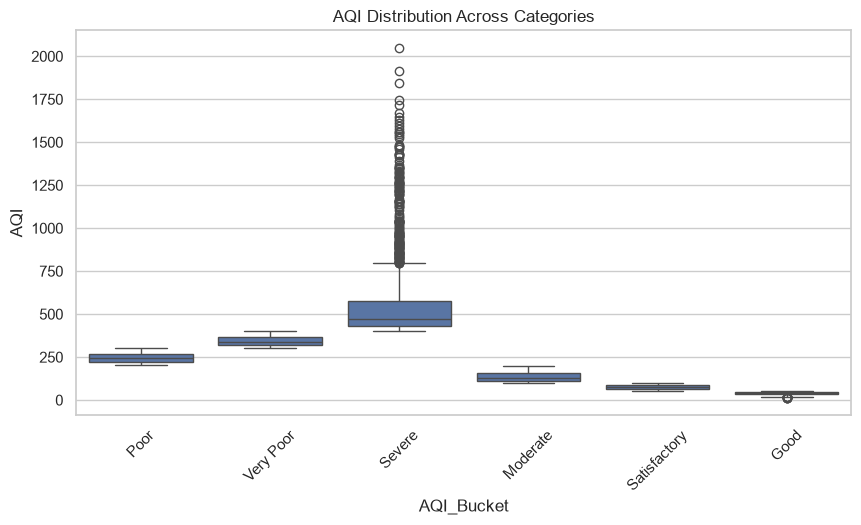

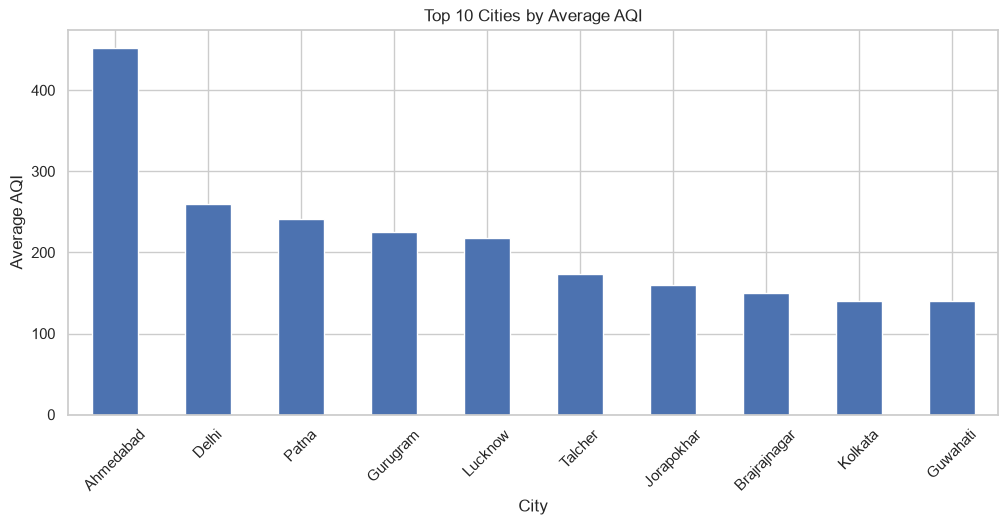

multivariate analysis

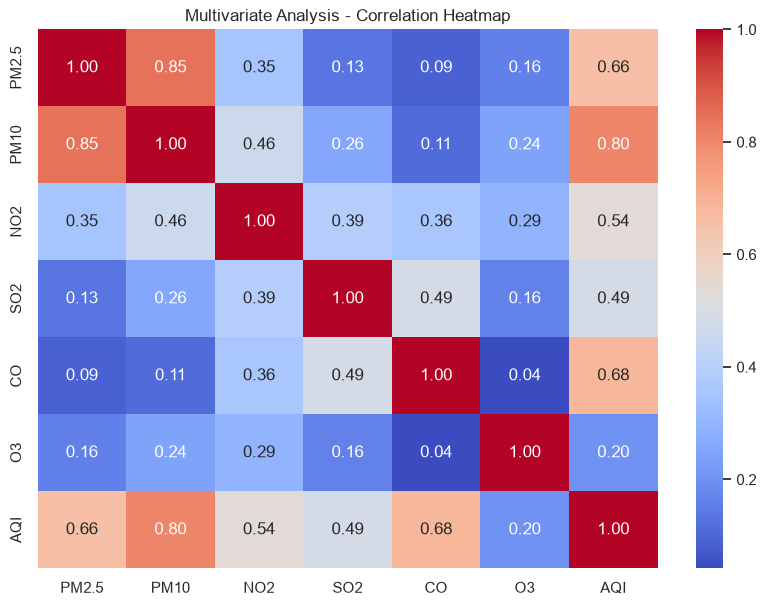

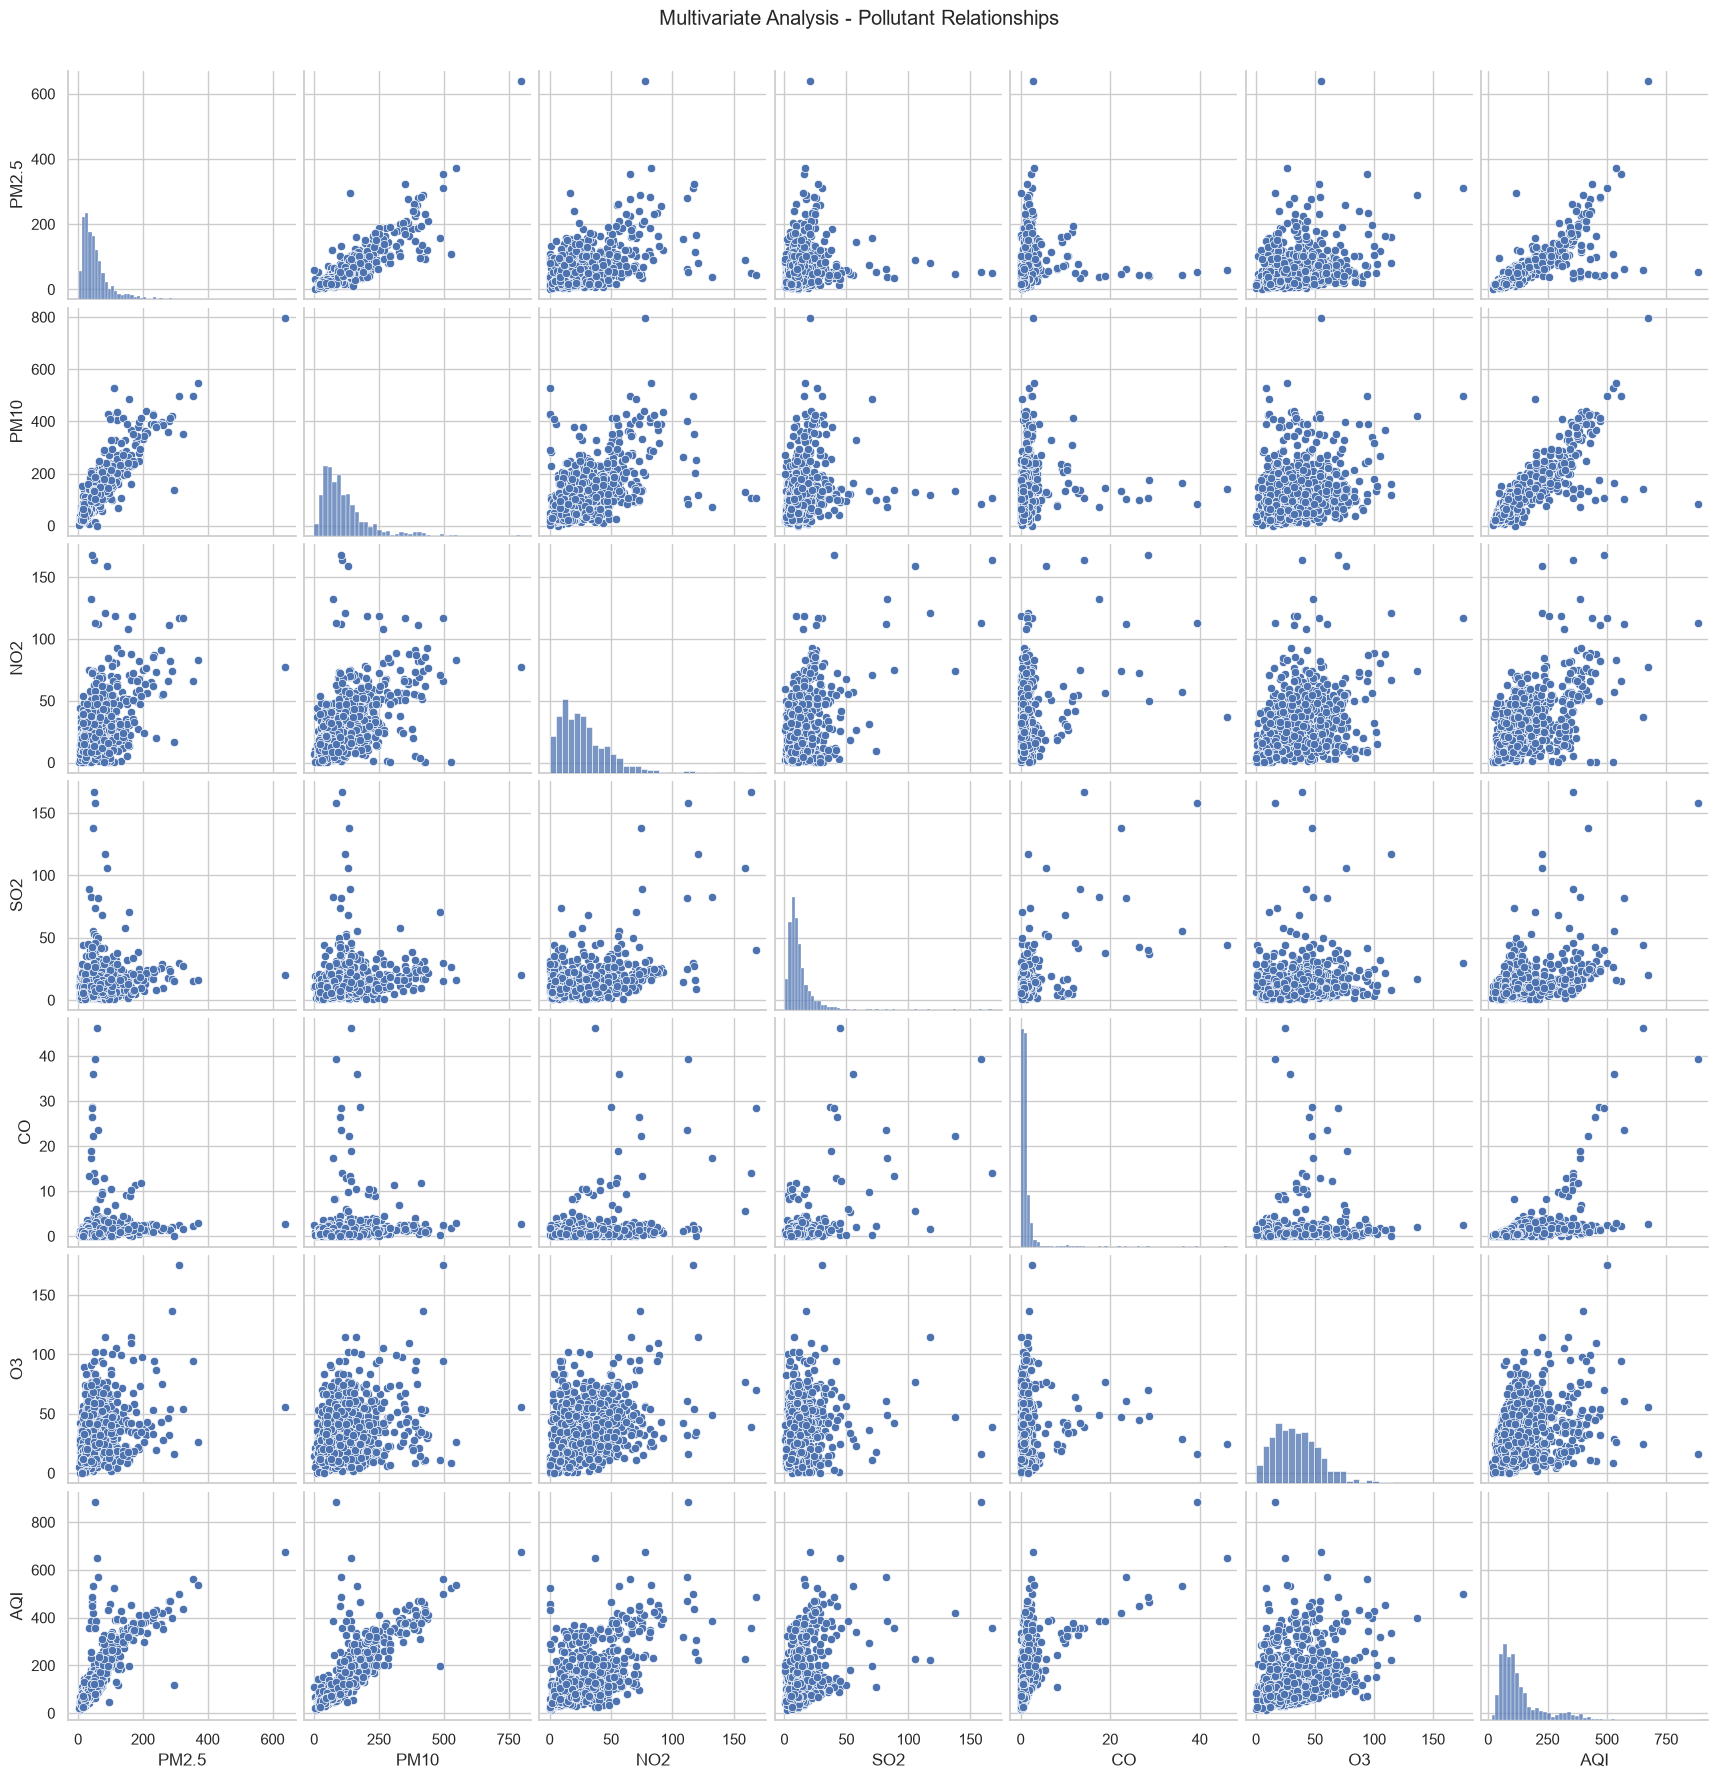

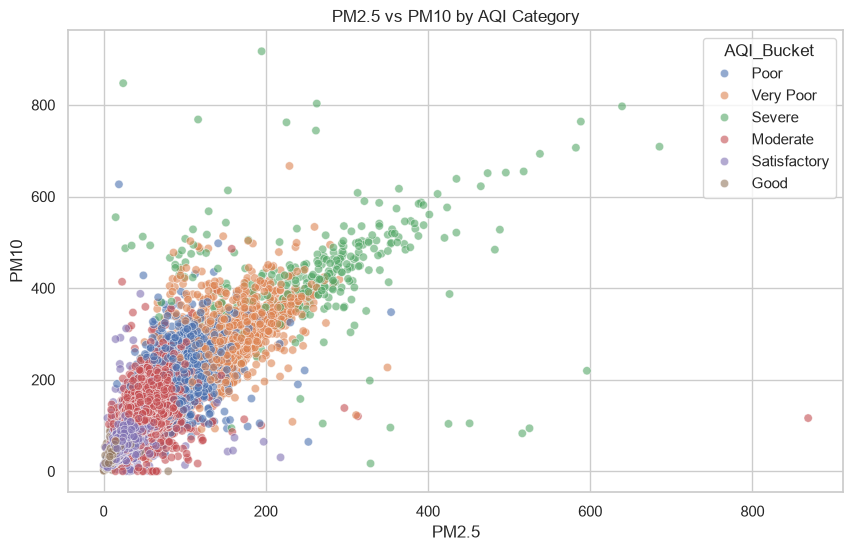

Correlation of pollutants with AQI:


AQI      1.000000
PM10     0.803313
CO       0.683346
PM2.5    0.659181
NO2      0.537071
SO2      0.490586
O3       0.198991
Name: AQI, dtype: float64

In [29]:
# MULTIVARIATE ANALYSIS

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

pollutants = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3"]

# 1. Correlation heatmap
numeric_data = df[pollutants + ["AQI"]]

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Multivariate Analysis - Correlation Heatmap")
plt.show()

# 2. Pairplot for pollutants and AQI
pair_data = df[pollutants + ["AQI"]].dropna()

# Sample 1000 rows for faster visualization
pair_data = pair_data.sample(
    min(1000, len(pair_data)),
    random_state=42
)

sns.pairplot(pair_data, diag_kind="hist")
plt.suptitle("Multivariate Analysis - Pollutant Relationships", y=1.02)
plt.show()

# 3. Multiple pollutants vs AQI by AQI category
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="PM2.5",
    y="PM10",
    hue="AQI_Bucket",
    alpha=0.6
)

plt.title("PM2.5 vs PM10 by AQI Category")
plt.show()

# 4. Correlation of pollutants with AQI
print("Correlation of pollutants with AQI:")

display(
    numeric_data.corr()["AQI"]
    .sort_values(ascending=False)
)

Preprocessing

In [30]:
# PREPROCESSING STEP 1: Remove rows with missing AQI

df_clean = df.copy()

df_clean["Date"] = pd.to_datetime(df_clean["Date"])

df_clean = df_clean.dropna(subset=["AQI"])

print("Original dataset shape:", df.shape)
print("After removing missing AQI:", df_clean.shape)
print("Missing AQI remaining:", df_clean["AQI"].isnull().sum())

Original dataset shape: (29531, 16)
After removing missing AQI: (24850, 16)
Missing AQI remaining: 0


In [31]:
features = [
    "City",
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene",
    "Xylene"
]

target = "AQI"

df_model = df_clean[features + [target]].copy()

print("Model dataset shape:", df_model.shape)

df_model.head()

Model dataset shape: (24850, 14)


,City,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
28,Ahmedabad,83.13,NaN,6.93,28.71,33.72,NaN,6.93,49.52,59.76,0.02,0.00,3.14,209.0
29,Ahmedabad,79.84,NaN,13.85,28.68,41.08,NaN,13.85,48.49,97.07,0.04,0.00,4.81,328.0
30,Ahmedabad,94.52,NaN,24.39,32.66,52.61,NaN,24.39,67.39,111.33,0.24,0.01,7.67,514.0
31,Ahmedabad,135.99,NaN,43.48,42.08,84.57,NaN,43.48,75.23,102.70,0.40,0.04,25.87,782.0
32,Ahmedabad,178.33,NaN,54.56,35.31,72.80,NaN,54.56,55.04,107.38,0.46,0.06,35.61,914.0


In [32]:
df_model.isnull().sum().sort_values(ascending=False)

Xylene     15372
PM10        7086
NH3         6536
Toluene     5826
Benzene     3535
NOx         1857
O3           807
PM2.5        678
SO2          605
CO           445
NO2          391
NO           387
City           0
AQI            0
dtype: int64

In [34]:
# Chronological train-test split (80% training, 20% testing)

unique_dates = sorted(df_model["Date"].unique())

split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_index]

train_data = df_model[df_model["Date"] < split_date].copy()
test_data = df_model[df_model["Date"] >= split_date].copy()

print("Split date:", split_date)
print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)

print("Training date range:",
      train_data["Date"].min(), "to", train_data["Date"].max())

print("Testing date range:",
      test_data["Date"].min(), "to", test_data["Date"].max())

KeyError: 'Date'

In [35]:
df_model = df_clean[features + [target]].copy()

In [36]:
# Include Date for chronological splitting
df_model = df_clean[["Date"] + features + [target]].copy()

print("Columns:", df_model.columns.tolist())
print("Shape:", df_model.shape)

Columns: ['Date', 'City', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI']
Shape: (24850, 15)


In [37]:
unique_dates = sorted(df_model["Date"].unique())

split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_index]

train_data = df_model[df_model["Date"] < split_date].copy()
test_data = df_model[df_model["Date"] >= split_date].copy()

print("Split date:", split_date)
print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)

print("Training dates:",
      train_data["Date"].min(), "to", train_data["Date"].max())

print("Testing dates:",
      test_data["Date"].min(), "to", test_data["Date"].max())

Split date: 2019-05-27 00:00:00
Training data: (16018, 15)
Testing data: (8832, 15)
Training dates: 2015-01-01 00:00:00 to 2019-05-26 00:00:00
Testing dates: 2019-05-27 00:00:00 to 2020-07-01 00:00:00


In [38]:
X_train = train_data[features].copy()
X_test = test_data[features].copy()

y_train = train_data[target].copy()
y_test = test_data[target].copy()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16018, 13)
X_test: (8832, 13)
y_train: (16018,)
y_test: (8832,)


In [39]:
# Fit preprocessing using training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same preprocessing to test data
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")

print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)

NameError: name 'preprocessor' is not defined

In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features = [col for col in features if col != "City"]
categorical_features = ["City"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [41]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (16018, 31)
Testing shape: (8832, 31)


In [42]:
import numpy as np

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("Missing values in training:",
      np.isnan(X_train_processed).any())

print("Missing values in testing:",
      np.isnan(X_test_processed).any())

print("Missing values in y_train:", y_train.isnull().sum())
print("Missing values in y_test:", y_test.isnull().sum())

Training data shape: (16018, 31)
Testing data shape: (8832, 31)
Missing values in training: False
Missing values in testing: False
Missing values in y_train: 0
Missing values in y_test: 0


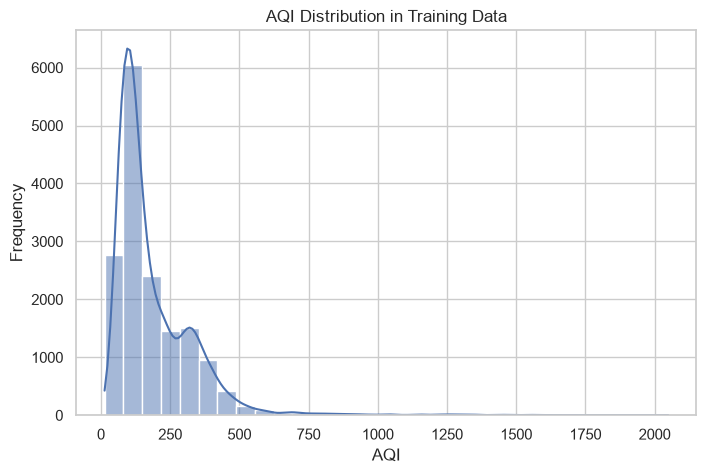

In [43]:
plt.figure(figsize=(8, 5))

sns.histplot(y_train, bins=30, kde=True)

plt.title("AQI Distribution in Training Data")
plt.xlabel("AQI")
plt.ylabel("Frequency")

plt.show()

regression

In [44]:
# LINEAR REGRESSION - AQI PROJECT

import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create Linear Regression pipeline
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train model
linear_model.fit(X_train, y_train)

# Predict AQI
y_pred = linear_model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("========== LINEAR REGRESSION RESULTS ==========")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R2 Score: {r2:.4f}")

# Compare actual and predicted AQI
import pandas as pd

results = pd.DataFrame({
    "Actual AQI": y_test.values,
    "Predicted AQI": y_pred
})

print("\nSample Predictions:")
display(results.head(10))

========== LINEAR REGRESSION RESULTS ==========
Training samples: 16018
Testing samples: 8832
MAE  : 24.48
MSE  : 1370.97
RMSE : 37.03
R2 Score: 0.8731

Sample Predictions:


,Actual AQI,Predicted AQI
0,435.0,534.630025
1,440.0,503.257483
2,374.0,410.966972
3,515.0,496.054127
4,360.0,455.890981
5,467.0,522.129369
6,402.0,483.808948
7,419.0,503.554290
8,408.0,484.406031
9,402.0,432.744932


In [45]:
# DECISION TREE REGRESSION - AQI PROJECT

import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create Decision Tree pipeline
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
        random_state=42,
        max_depth=10
    ))
])

# Train model
decision_tree_model.fit(X_train, y_train)

# Predict AQI
y_pred_dt = decision_tree_model.predict(X_test)

# Evaluate model
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

# Display results
print("========== DECISION TREE REGRESSION RESULTS ==========")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"MAE  : {mae_dt:.2f}")
print(f"MSE  : {mse_dt:.2f}")
print(f"RMSE : {rmse_dt:.2f}")
print(f"R2 Score: {r2_dt:.4f}")

# Compare actual and predicted AQI
import pandas as pd

results_dt = pd.DataFrame({
    "Actual AQI": y_test.values,
    "Predicted AQI": y_pred_dt
})

print("\nSample Predictions:")
display(results_dt.head(10))

========== DECISION TREE REGRESSION RESULTS ==========
Training samples: 16018
Testing samples: 8832
MAE  : 20.55
MSE  : 1711.78
RMSE : 41.37
R2 Score: 0.8416

Sample Predictions:


,Actual AQI,Predicted AQI
0,435.0,456.223881
1,440.0,456.223881
2,374.0,333.307692
3,515.0,456.223881
4,360.0,813.000000
5,467.0,456.223881
6,402.0,456.223881
7,419.0,456.223881
8,408.0,345.333333
9,402.0,345.333333


In [46]:
# RANDOM FOREST REGRESSION - AQI PROJECT

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create model pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
random_forest_model.fit(X_train, y_train)

# Predict AQI
y_pred_rf = random_forest_model.predict(X_test)

# Evaluate model
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

# Display results
print("========== RANDOM FOREST REGRESSION RESULTS ==========")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"MAE  : {mae_rf:.2f}")
print(f"MSE  : {mse_rf:.2f}")
print(f"RMSE : {rmse_rf:.2f}")
print(f"R2 Score: {r2_rf:.4f}")

# Show actual vs predicted AQI
results_rf = pd.DataFrame({
    "Actual AQI": y_test.values,
    "Predicted AQI": y_pred_rf
})

display(results_rf.head(10))

========== RANDOM FOREST REGRESSION RESULTS ==========
Training samples: 16018
Testing samples: 8832
MAE  : 17.80
MSE  : 1036.52
RMSE : 32.20
R2 Score: 0.9041


,Actual AQI,Predicted AQI
0,435.0,559.37
1,440.0,537.14
2,374.0,392.80
3,515.0,481.97
4,360.0,419.86
5,467.0,485.54
6,402.0,478.01
7,419.0,502.64
8,408.0,450.09
9,402.0,382.87


In [47]:
# KNN REGRESSION - AQI PROJECT

import numpy as np
import pandas as pd

from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create KNN pipeline
knn_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=5))
])

# Train model
knn_model.fit(X_train, y_train)

# Predict AQI
y_pred_knn = knn_model.predict(X_test)

# Evaluate model
mae_knn = mean_absolute_error(y_test, y_pred_knn)
mse_knn = mean_squared_error(y_test, y_pred_knn)
rmse_knn = np.sqrt(mse_knn)
r2_knn = r2_score(y_test, y_pred_knn)

# Display results
print("========== KNN REGRESSION RESULTS ==========")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"MAE  : {mae_knn:.2f}")
print(f"MSE  : {mse_knn:.2f}")
print(f"RMSE : {rmse_knn:.2f}")
print(f"R2 Score: {r2_knn:.4f}")

# Show actual vs predicted AQI
results_knn = pd.DataFrame({
    "Actual AQI": y_test.values,
    "Predicted AQI": y_pred_knn
})

display(results_knn.head(10))

========== KNN REGRESSION RESULTS ==========
Training samples: 16018
Testing samples: 8832
MAE  : 30.80
MSE  : 2772.09
RMSE : 52.65
R2 Score: 0.7435


,Actual AQI,Predicted AQI
0,435.0,470.4
1,440.0,393.8
2,374.0,425.6
3,515.0,385.4
4,360.0,385.4
5,467.0,385.4
6,402.0,385.4
7,419.0,385.4
8,408.0,519.2
9,402.0,292.0


In [48]:
# SUPPORT VECTOR REGRESSION (SVR) - AQI PROJECT

import numpy as np
import pandas as pd

from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create SVR pipeline
svr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("scaler", StandardScaler()),
    ("model", SVR(kernel="rbf", C=100, epsilon=0.1))
])

# Train model
svr_model.fit(X_train, y_train)

# Predict AQI
y_pred_svr = svr_model.predict(X_test)

# Evaluate model
mae_svr = mean_absolute_error(y_test, y_pred_svr)
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, y_pred_svr)

# Display results
print("========== SVR RESULTS ==========")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"MAE  : {mae_svr:.2f}")
print(f"MSE  : {mse_svr:.2f}")
print(f"RMSE : {rmse_svr:.2f}")
print(f"R2 Score: {r2_svr:.4f}")

# Show actual vs predicted AQI
results_svr = pd.DataFrame({
    "Actual AQI": y_test.values,
    "Predicted AQI": y_pred_svr
})

display(results_svr.head(10))

========== SVR RESULTS ==========
Training samples: 16018
Testing samples: 8832
MAE  : 40.71
MSE  : 4486.90
RMSE : 66.98
R2 Score: 0.5848


,Actual AQI,Predicted AQI
0,435.0,455.686372
1,440.0,472.782385
2,374.0,394.741109
3,515.0,396.786269
4,360.0,339.809568
5,467.0,398.488687
6,402.0,380.038997
7,419.0,392.114297
8,408.0,358.643434
9,402.0,328.875874


In [49]:
# GRADIENT BOOSTING REGRESSION - AQI PROJECT

import numpy as np
import pandas as pd

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create model pipeline
gradient_boosting_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train model
gradient_boosting_model.fit(X_train, y_train)

# Predict AQI
y_pred_gb = gradient_boosting_model.predict(X_test)

# Evaluate model
mae_gb = mean_absolute_error(y_test, y_pred_gb)
mse_gb = mean_squared_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mse_gb)
r2_gb = r2_score(y_test, y_pred_gb)

# Display results
print("========== GRADIENT BOOSTING REGRESSION RESULTS ==========")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"MAE  : {mae_gb:.2f}")
print(f"MSE  : {mse_gb:.2f}")
print(f"RMSE : {rmse_gb:.2f}")
print(f"R2 Score: {r2_gb:.4f}")

# Show actual vs predicted AQI
results_gb = pd.DataFrame({
    "Actual AQI": y_test.values,
    "Predicted AQI": y_pred_gb
})

display(results_gb.head(10))

========== GRADIENT BOOSTING REGRESSION RESULTS ==========
Training samples: 16018
Testing samples: 8832
MAE  : 18.27
MSE  : 960.56
RMSE : 30.99
R2 Score: 0.9111


,Actual AQI,Predicted AQI
0,435.0,435.805622
1,440.0,545.175950
2,374.0,419.065115
3,515.0,579.251932
4,360.0,396.292498
5,467.0,495.012988
6,402.0,509.063071
7,419.0,552.475146
8,408.0,523.296807
9,402.0,451.883306


In [50]:


# AQI PROJECT - MODEL COMPARISON

import pandas as pd
import numpy as np

# Store results from all six models
model_results = {
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "SVR",
        "Gradient Boosting"
    ],
    "MAE": [
        mae, mae_dt, mae_rf, mae_knn, mae_svr, mae_gb
    ],
    "MSE": [
        mse, mse_dt, mse_rf, mse_knn, mse_svr, mse_gb
    ],
    "RMSE": [
        rmse, rmse_dt, rmse_rf, rmse_knn, rmse_svr, rmse_gb
    ],
    "R2 Score": [
        r2, r2_dt, r2_rf, r2_knn, r2_svr, r2_gb
    ]
}

comparison_df = pd.DataFrame(model_results)

# Sort by lowest RMSE
comparison_df = comparison_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("========== AQI MODEL COMPARISON ==========")
display(comparison_df.round(4))

# Identify best model
best_model_name = comparison_df.iloc[0]["Model"]

print("\nBest model based on lowest RMSE:", best_model_name)

========== AQI MODEL COMPARISON ==========


,Model,MAE,MSE,RMSE,R2 Score
0,Gradient Boosting,18.2689,960.5582,30.9929,0.9111
1,Random Forest,17.7958,1036.5226,32.1951,0.9041
2,Linear Regression,24.4784,1370.9728,37.0267,0.8731
3,Decision Tree,20.5460,1711.7755,41.3736,0.8416
4,KNN,30.8028,2772.0903,52.6506,0.7435
5,SVR,40.7099,4486.9038,66.9844,0.5848



Best model based on lowest RMSE: Gradient Boosting


Hyperparameter Optimization

In [51]:
# HYPERPARAMETER OPTIMIZATION - GRADIENT BOOSTING

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Create pipeline
gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(random_state=42))
])

# Hyperparameter combinations
param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3, 4]
}

# Grid Search
grid_search_gb = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

# Train Grid Search
grid_search_gb.fit(X_train, y_train)

# Best model
best_gb_model = grid_search_gb.best_estimator_

# Predictions
y_pred_best_gb = best_gb_model.predict(X_test)

# Evaluation
print("Best Parameters:", grid_search_gb.best_params_)
print("Best CV RMSE:", -grid_search_gb.best_score_)
print("Test MAE:", mean_absolute_error(y_test, y_pred_best_gb))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_best_gb)))
print("Test R2:", r2_score(y_test, y_pred_best_gb))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__n_estimators': 100}
Best CV RMSE: 84.11765471997687
Test MAE: 17.76171945008793
Test RMSE: 31.641766056036268
Test R2: 0.9073604633774133


In [52]:
# OPTIMIZED GRADIENT BOOSTING RESULTS

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

optimized_gb_results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2 Score"],
    "Original Gradient Boosting": [
        mae_gb, mse_gb, rmse_gb, r2_gb
    ],
    "Optimized Gradient Boosting": [
        mean_absolute_error(y_test, y_pred_best_gb),
        mean_squared_error(y_test, y_pred_best_gb),
        np.sqrt(mean_squared_error(y_test, y_pred_best_gb)),
        r2_score(y_test, y_pred_best_gb)
    ]
})

print("Best Parameters:", grid_search_gb.best_params_)
display(optimized_gb_results.round(4))

Best Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__n_estimators': 100}


,Metric,Original Gradient Boosting,Optimized Gradient Boosting
0,MAE,18.2689,17.7617
1,MSE,960.5582,1001.2014
2,RMSE,30.9929,31.6418
3,R2 Score,0.9111,0.9074


Tune Random Forest

In [53]:
# RANDOM FOREST HYPERPARAMETER OPTIMIZATION

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42, n_jobs=-1))
])

# Hyperparameter search space
param_dist = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [10, 20, 30, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

# Randomized Search
random_search_rf = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

# Train
random_search_rf.fit(X_train, y_train)

# Best model
best_rf_model = random_search_rf.best_estimator_

# Predict
y_pred_best_rf = best_rf_model.predict(X_test)

# Evaluate
print("Best Parameters:", random_search_rf.best_params_)
print("Best CV RMSE:", -random_search_rf.best_score_)
print("Test MAE:", mean_absolute_error(y_test, y_pred_best_rf))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_best_rf)))
print("Test R2:", r2_score(y_test, y_pred_best_rf))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters: {'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_depth': 20}
Best CV RMSE: 84.24348719459056
Test MAE: 17.668342012358398
Test RMSE: 31.729040907084645
Test R2: 0.9068487187436034


In [54]:
# SAVE FINAL AQI MODEL

import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(gradient_boosting_model, "../models/aqi_model.pkl")

print("Original Gradient Boosting model saved successfully!")
print("Location: models/aqi_model.pkl")

Original Gradient Boosting model saved successfully!
Location: models/aqi_model.pkl


Flask Website Development.

In [55]:
# FINAL AQI MODEL COMPARISON

import pandas as pd

final_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "SVR",
        "Gradient Boosting",
        "Optimized Gradient Boosting",
        "Optimized Random Forest"
    ],
    "MAE": [
        mae, mae_dt, mae_rf, mae_knn, mae_svr, mae_gb,
        mean_absolute_error(y_test, y_pred_best_gb),
        mean_absolute_error(y_test, y_pred_best_rf)
    ],
    "RMSE": [
        rmse, rmse_dt, rmse_rf, rmse_knn, rmse_svr, rmse_gb,
        np.sqrt(mean_squared_error(y_test, y_pred_best_gb)),
        np.sqrt(mean_squared_error(y_test, y_pred_best_rf))
    ],
    "R2 Score": [
        r2, r2_dt, r2_rf, r2_knn, r2_svr, r2_gb,
        r2_score(y_test, y_pred_best_gb),
        r2_score(y_test, y_pred_best_rf)
    ]
})

final_comparison = final_comparison.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(final_comparison.round(4))

# Save comparison results
final_comparison.to_csv("../models/model_comparison.csv", index=False)

print("Final comparison saved to models/model_comparison.csv")

,Model,MAE,RMSE,R2 Score
0,Gradient Boosting,18.2689,30.9929,0.9111
1,Optimized Gradient Boosting,17.7617,31.6418,0.9074
2,Optimized Random Forest,17.6683,31.7290,0.9068
3,Random Forest,17.7958,32.1951,0.9041
4,Linear Regression,24.4784,37.0267,0.8731
5,Decision Tree,20.5460,41.3736,0.8416
6,KNN,30.8028,52.6506,0.7435
7,SVR,40.7099,66.9844,0.5848


Final comparison saved to models/model_comparison.csv
